## Asset Class Galaxy


### Settings


In [1]:
# Set refresh_timeseries=True to download timeseries. Otherwise symbol-cache is used.
refresh_timeseries = False
throttle_limit = 100
wait_time = 30


In [2]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}


<IPython.core.display.Javascript object>

### Build asset-classes.csv


AGG 

AOA 

AOK 

AOM 

AOR 

...

XLP 

XLRE 

XLU 

XLV 

XLY 

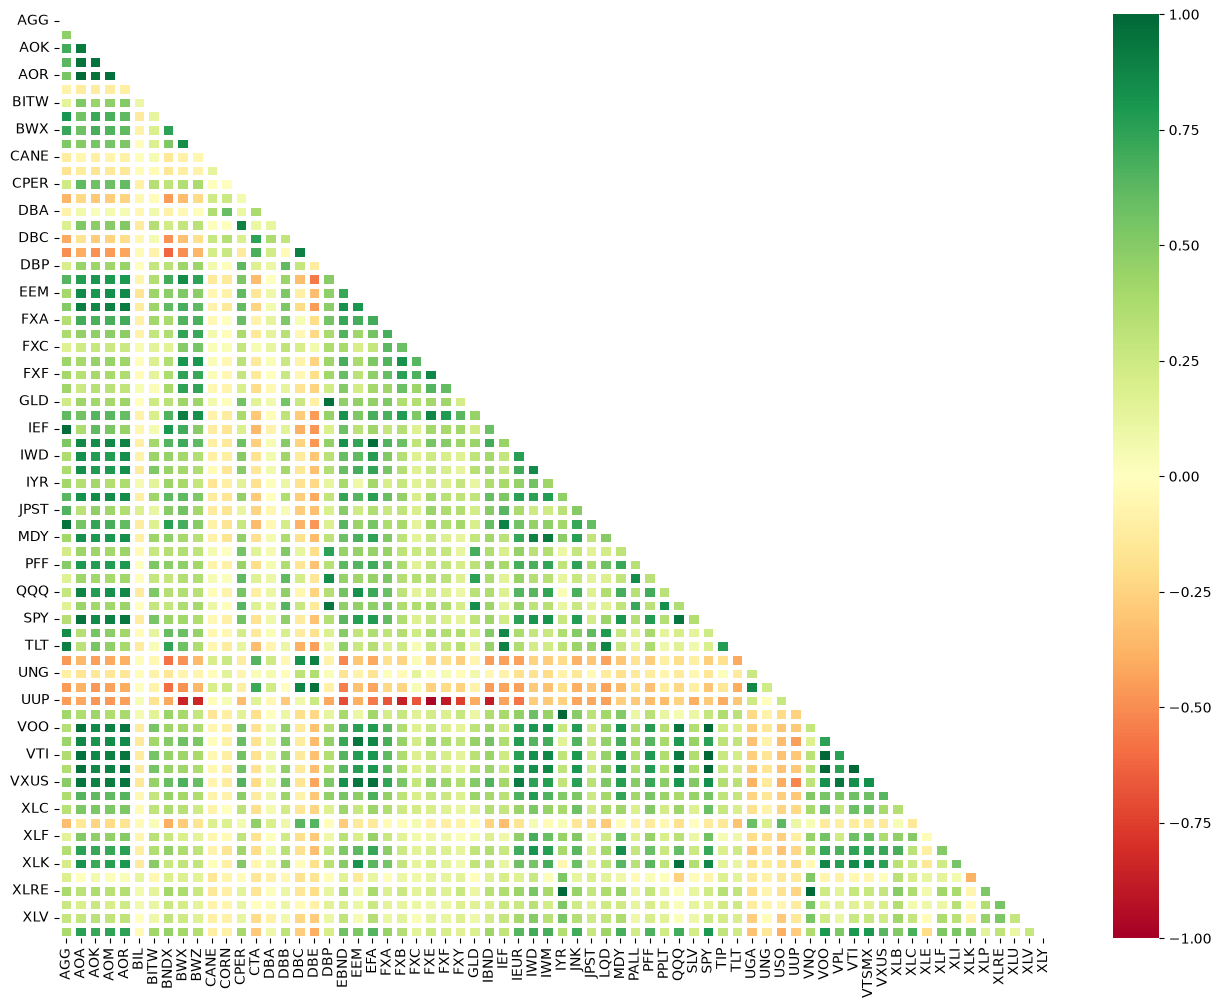

In [3]:
from pathlib import Path

import pandas as pd

import brownbear as bb

bb.notebook_display_options()

directory = Path('.')

# asset2etf maps each asset class to a representative ETF.
asset2etf = pd.read_csv('asset-classes-2-etf.csv', skip_blank_lines=True, comment='#')
asset2etf = asset2etf.set_index(['Asset Class'])['ETF'].to_dict()
symbols = sorted(set(asset2etf.values()))

bb.fetch_timeseries(symbols, refresh=refresh_timeseries, throttle_limit=throttle_limit, wait_time=wait_time)
bb.compile_timeseries(symbols, output_path=directory / 'symbols-timeseries.csv')

df = pd.read_csv('symbols-timeseries.csv', skip_blank_lines=True, comment='#')
df.set_index("Date", inplace=True)

corr_map = bb.correlation_map(df, method='log', days=bb.TRADING_DAYS_PER_YEAR)

with open('asset-classes-in.csv') as f:
    lines = [line.strip() for line in f]

out = []
for line in lines:
    if not line or line.startswith('#'):
        out.append(line)
        continue
    fields = [field.strip() for field in line.split(',')]
    assetA = fields[0].strip('"')
    assetB = fields[1].strip('"')
    if assetA == assetB or assetA == 'Asset Class A':
        out.append(line)
        continue
    etfA = asset2etf[assetA]
    etfB = asset2etf[assetB]
    corrAB = corr_map.loc[etfA, etfB]
    out.append(f'"{assetA}","{assetB}","{corrAB:0.2f}"')

with open('asset-classes.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')


### Build investment-options.csv


In [4]:
import numpy as np

metrics = bb.compute_investment_metrics(df)

with open('investment-options-in.csv') as f:
    out = [line.strip() for line in f]

for asset_class, symbol in asset2etf.items():
    ret_3mo = metrics['annual_returns_3mo'][symbol]
    ret_6mo = metrics['annual_returns_6mo'][symbol]
    ret_1yr = metrics['annual_returns_1yr'][symbol]
    ret_1_1yr = metrics['annual_returns_1_1yr'][symbol]
    ret_3yr = metrics['annual_returns_3yr'][symbol]
    ret_5yr = metrics['annual_returns_5yr'][symbol]
    if np.isnan(ret_3yr):
        ret_3yr = ret_1yr
    if np.isnan(ret_5yr):
        ret_5yr = ret_3yr
    vola = metrics['vola'][symbol] * 100
    ds_vola = metrics['ds_vola'][symbol] * 100
    sd_1yr = metrics['std_dev_1yr'][symbol] * 100
    sd_3yr = metrics['std_dev_3yr'][symbol] * 100
    sd_5yr = metrics['std_dev_5yr'][symbol] * 100
    out.append(
        f'"{asset_class}","{asset_class}","{asset_class}",'
        f'"{ret_3mo:0.2f}","{ret_6mo:0.2f}","{ret_1yr:0.2f}","{ret_1_1yr:0.2f}","{ret_3yr:0.2f}",'
        f'"{ret_5yr:0.2f}","{vola:0.2f}","{ds_vola:0.2f}","{sd_1yr:0.2f}","{sd_3yr:0.2f}","{sd_5yr:0.2f}"'
    )

with open('investment-options.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')

investment_options = pd.read_csv('investment-options.csv', skip_blank_lines=True, comment='#')
investment_options


,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr
0,US Stocks,US Stocks,US Stocks,20.95,15.27,18.44,16.16,18.73,11.66,11.76,6.99,12.50,13.35,16.04
1,Global Stocks,Global Stocks,Global Stocks,20.75,11.46,25.46,21.87,17.20,8.81,18.37,9.37,13.39,12.33,15.05
2,US Bonds,US Bonds,US Bonds,-1.43,-1.15,2.74,3.22,3.80,-0.32,3.50,2.38,3.14,5.54,6.39
3,Global Bonds,Global Bonds,Global Bonds,3.02,0.12,1.38,1.35,3.90,0.03,3.68,2.42,3.22,4.15,5.29
4,Cash Equivalents,Cash Equivalents,Cash Equivalents,3.68,3.62,3.79,3.79,4.59,3.53,0.22,0.04,0.11,0.21,0.54
5,Real Estate,Real Estate,Real Estate,25.11,28.58,12.68,15.84,9.10,2.81,15.25,6.93,13.09,16.62,18.98
6,Commodities,Commodities,Commodities,-20.80,38.21,33.57,35.76,10.82,12.08,24.26,13.43,22.76,15.95,17.04
7,Currencies,Currencies,Currencies,7.90,11.66,5.55,6.87,4.90,5.50,5.69,4.24,5.40,6.86,7.08
8,Managed Futures,Managed Futures,Managed Futures,-49.44,-7.07,0.25,1.13,8.31,8.31,28.92,17.25,19.19,15.36,16.79
9,Balanced,Balanced,Balanced,7.93,5.00,9.99,9.15,9.80,4.49,7.41,4.42,6.14,7.15,8.91
